[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic02_constrained_optimization_figures.ipynb)

# Topic 2: Constrained Optimization -- Figure Generator

This notebook regenerates, from their underlying formulas, every static figure
used in [`slides/02_constrained-optimization/deck.md`](../slides/02_constrained-optimization/deck.md)
(slides 43-63, "Mathematical Preliminaries"). It's a proof of concept for
replacing opaque PNGs extracted from the original PowerPoint deck with
figures generated directly from code -- so the math and the picture can never
drift apart, and so the same code can power a live, interactive version for
class.

**Two things this notebook does:**

1. **Static figures** -- one cell per slide image, saved to `../slides/02_constrained-optimization/figs/`
   under this `notebooks/` folder (not yet wired back into the deck -- that's
   a separate decision once these are reviewed).
2. **Interactive demos** -- a few richer examples (profit maximization, the
   isoquant/MRTS diagram, a rotatable 3-D surface) built with `ipywidgets`
   and `plotly` for live use in class.

Run with the `ecopy` kernel (`mamba run -n ecopy jupyter lab`), which already
has `numpy`, `matplotlib`, `ipywidgets`, and `plotly` installed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/02_constrained-optimization/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

## Single-Variable Optimization

saved ..\slides\02_constrained-optimization\figs\profit-max-graph.png


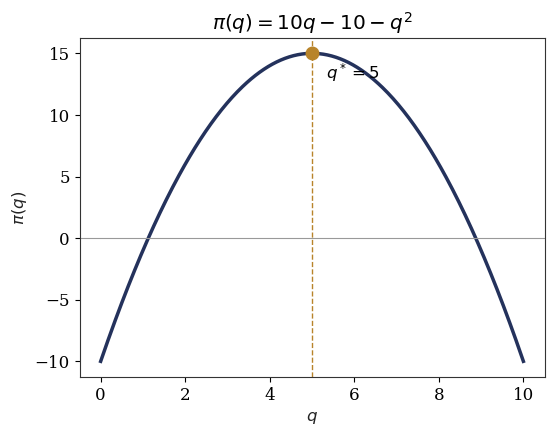

In [2]:
q = np.linspace(0, 10, 400)
pi = 10 * q - 10 - q**2
qstar = 5

fig, ax = plt.subplots(figsize=(6.0, 4.4))
ax.plot(q, pi, color=NAVY, lw=2.5)
ax.axvline(qstar, color=AMBER, lw=1, ls="--")
ax.plot(qstar, 10*qstar - 10 - qstar**2, "o", color=AMBER, ms=9, zorder=5)
ax.annotate(f"$q^*={qstar}$", (qstar, 10*qstar - 10 - qstar**2),
            textcoords="offset points", xytext=(10, -18), fontsize=12)
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlabel("$q$"); ax.set_ylabel(r"$\pi(q)$")
ax.set_title(r"$\pi(q) = 10q - 10 - q^2$")
savefig(fig, "profit-max-graph.png")
plt.show()

saved ..\slides\02_constrained-optimization\figs\quadratic-min-graph.png


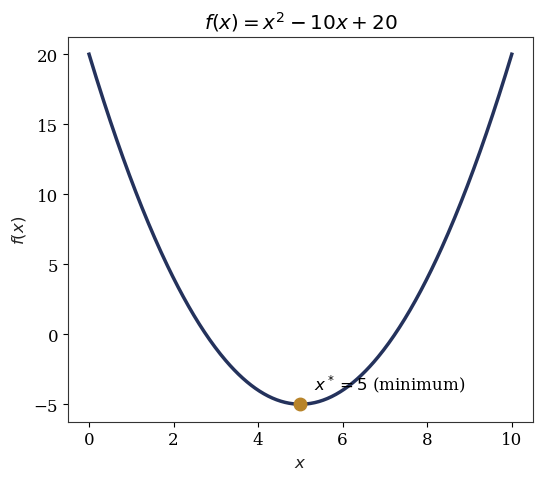

In [3]:
x = np.linspace(0, 10, 400)
f = x**2 - 10*x + 20
xstar = 5

fig, ax = plt.subplots(figsize=(6.0, 5.0))
ax.plot(x, f, color=NAVY, lw=2.5)
ax.plot(xstar, xstar**2 - 10*xstar + 20, "o", color=AMBER, ms=9, zorder=5)
ax.annotate(f"$x^*={xstar}$ (minimum)", (xstar, xstar**2 - 10*xstar + 20),
            textcoords="offset points", xytext=(10, 10), fontsize=12)
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
ax.set_title(r"$f(x) = x^2 - 10x + 20$")
savefig(fig, "quadratic-min-graph.png")
plt.show()

The deck's "Necessary and Sufficient Conditions" slide doesn't pin down a
specific cubic -- it just needs one local max and one local min to
illustrate the second-order condition. `f(x) = -x^3 + 3x^2 + 9x - 5` has
clean critical points at $x=-1$ (min) and $x=3$ (max).

saved ..\slides\02_constrained-optimization\figs\cubic-max-min-graph.png


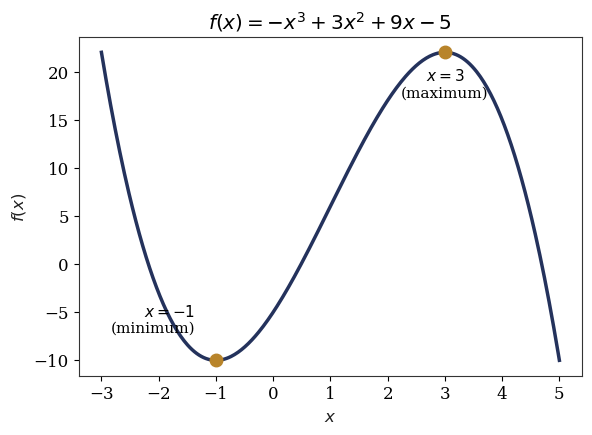

In [4]:
x = np.linspace(-3, 5, 400)
f = -x**3 + 3*x**2 + 9*x - 5

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.plot(x, f, color=NAVY, lw=2.5)
# Maximum at x = 3: text placed below the peak
ax.plot(3, 22, "o", color=AMBER, ms=9, zorder=5)
ax.annotate("$x=3$\n(maximum)", (3, 22), textcoords="offset points",
            xytext=(0, -32), ha="center", fontsize=11)
# Minimum at x = -1: text placed more to the left and above
ax.plot(-1, -10, "o", color=AMBER, ms=9, zorder=5)
ax.annotate("$x=-1$\n(minimum)", (-1, -10), textcoords="offset points",
            xytext=(-15, 20), ha="right", fontsize=11)
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
ax.set_title(r"$f(x) = -x^3 + 3x^2 + 9x - 5$")
savefig(fig, "cubic-max-min-graph.png")
plt.show()

saved ..\slides\02_constrained-optimization\figs\cubic-inflection-graph.png


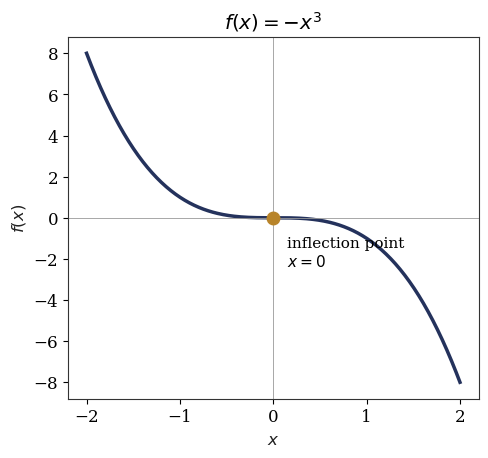

In [5]:
x = np.linspace(-2, 2, 400)
f = -x**3

fig, ax = plt.subplots(figsize=(5.3, 4.7))
ax.plot(x, f, color=NAVY, lw=2.5)
ax.plot(0, 0, "o", color=AMBER, ms=9, zorder=5)
ax.annotate("inflection point\n$x=0$", (0, 0), textcoords="offset points",
            xytext=(10, -35), fontsize=11)
ax.axhline(0, color="#999999", lw=0.6); ax.axvline(0, color="#999999", lw=0.6)
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
ax.set_title(r"$f(x) = -x^3$")
savefig(fig, "cubic-inflection-graph.png")
plt.show()

## Multivariable Functions

saved ..\slides\02_constrained-optimization\figs\multivar-surface-generic.png


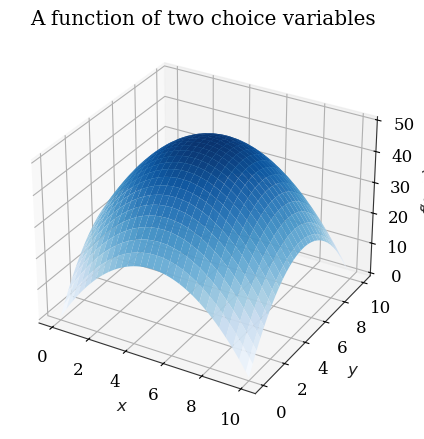

In [6]:
x = np.linspace(0, 10, 60); y = np.linspace(0, 10, 60)
X, Y = np.meshgrid(x, y)
Z = 50 - (X - 5)**2 - (Y - 5)**2

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap="Blues", edgecolor="none", alpha=0.95)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$f(x,y)$")
ax.set_title("A function of two choice variables")
savefig(fig, "multivar-surface-generic.png")
plt.show()

saved ..\slides\02_constrained-optimization\figs\surface-sqrt-3d.png


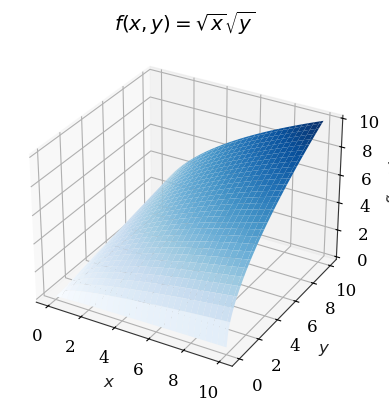

saved ..\slides\02_constrained-optimization\figs\contour-sqrt-2d.png


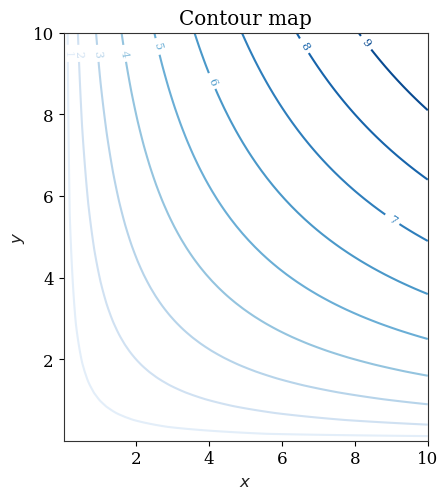

In [7]:
x = np.linspace(0.01, 10, 60); y = np.linspace(0.01, 10, 60)
X, Y = np.meshgrid(x, y)
Z = np.sqrt(X) * np.sqrt(Y)

fig = plt.figure(figsize=(4.5, 5.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap="Blues", edgecolor="none")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$f(x,y)$")
ax.set_title(r"$f(x,y)=\sqrt{x}\sqrt{y}$")
savefig(fig, "surface-sqrt-3d.png")
plt.show()

fig, ax = plt.subplots(figsize=(4.7, 5.3))
cs = ax.contour(X, Y, Z, levels=10, cmap="Blues")
ax.clabel(cs, inline=True, fontsize=8)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_title("Contour map")
savefig(fig, "contour-sqrt-2d.png")
plt.show()

saved ..\slides\02_constrained-optimization\figs\partial-derivatives-3panel.png


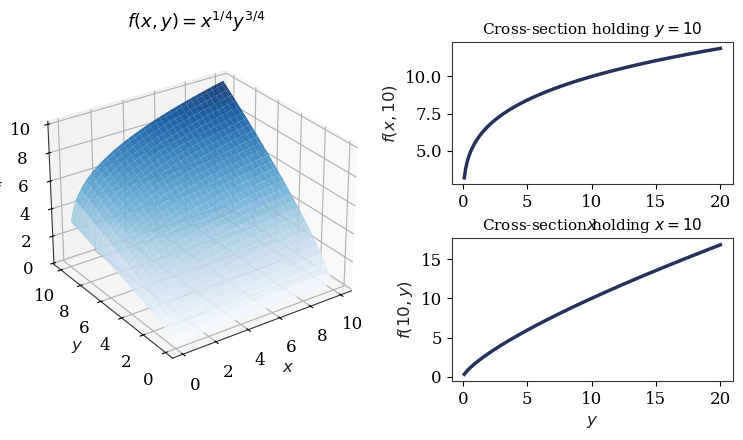

In [8]:
x = np.linspace(0.1, 10, 60); y = np.linspace(0.1, 10, 60)
X, Y = np.meshgrid(x, y)
Z = X**0.25 * Y**0.75

# 2-column layout: 3D surface on left (large!), 2 cross-sections on right
fig = plt.figure(figsize=(9.2, 4.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], hspace=0.38, wspace=0.25)

# Left: 3D Surface
ax1 = fig.add_subplot(gs[:, 0], projection="3d")
ax1.plot_surface(X, Y, Z, cmap="Blues", edgecolor="none", alpha=0.9)
ax1.set_xlabel("$x$", labelpad=2); ax1.set_ylabel("$y$", labelpad=2); ax1.set_zlabel("$f$", labelpad=2)
ax1.set_title(r"$f(x,y)=x^{1/4}y^{3/4}$", fontsize=13, pad=10)
ax1.view_init(elev=28, azim=-125)

# Right Top: Cross-section holding y = 10
xr = np.linspace(0.1, 20, 200)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(xr, xr**0.25 * 10**0.75, color=NAVY, lw=2.5)
ax2.set_xlabel("$x$"); ax2.set_ylabel("$f(x, 10)$")
ax2.set_title("Cross-section holding $y=10$", fontsize=11)

# Right Bottom: Cross-section holding x = 10
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(xr, 10**0.25 * xr**0.75, color=NAVY, lw=2.5)
ax3.set_xlabel("$y$"); ax3.set_ylabel("$f(10, y)$")
ax3.set_title("Cross-section holding $x=10$", fontsize=11)

savefig(fig, "partial-derivatives-3panel.png")
plt.show()

## Unconstrained Maximization

saved ..\slides\02_constrained-optimization\figs\unconstrained-max-surface.png


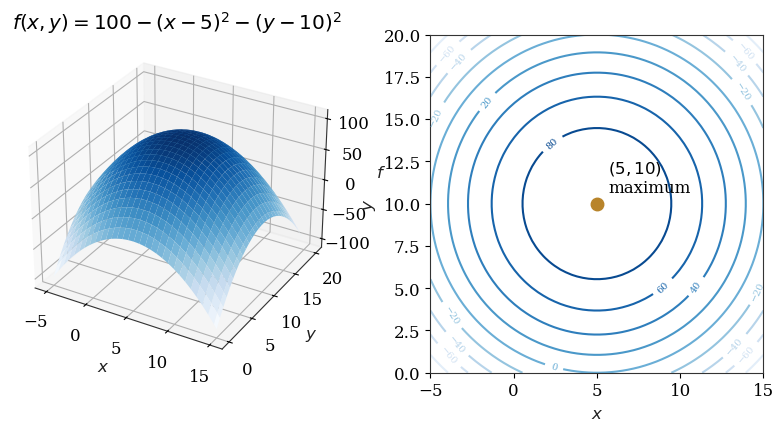

In [9]:
x = np.linspace(-5, 15, 60); y = np.linspace(0, 20, 60)
X, Y = np.meshgrid(x, y)
Z = 100 - (X - 5)**2 - (Y - 10)**2

fig = plt.figure(figsize=(8, 4.3))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, Z, cmap="Blues", edgecolor="none")
ax.scatter([5], [10], [100], color=AMBER, s=40)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$f$")
ax.set_title(r"$f(x,y)=100-(x-5)^2-(y-10)^2$")

ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(X, Y, Z, levels=12, cmap="Blues")
ax2.clabel(cs, inline=True, fontsize=7)
ax2.plot(5, 10, "o", color=AMBER, ms=9)
ax2.annotate("$(5,10)$\nmaximum", (5, 10), textcoords="offset points", xytext=(8, 8))
ax2.set_xlabel("$x$"); ax2.set_ylabel("$y$")
fig.tight_layout()
savefig(fig, "unconstrained-max-surface.png")
plt.show()

## Contour Lines and the Isoquant/MRTS Example

Matches the deck's worked example: $f(x,y)=xy$, the $q=100$ isoquant, and
the two tangent-line slopes computed in the text ($-1$ at $(10,10)$,
$-1/4$ at $(20,5)$) -- confirming the declining MRTS.

saved ..\slides\02_constrained-optimization\figs\isoquant-mrts-diagram.png


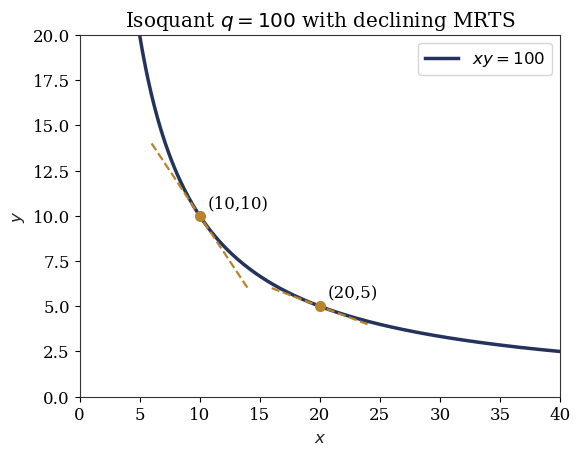

In [10]:
x = np.linspace(2, 50, 400)
y = 100 / x

fig, ax = plt.subplots(figsize=(6.2, 4.7))
ax.plot(x, y, color=NAVY, lw=2.5, label=r"$xy=100$")

for x0, slope, label in [(10, -1, "(10,10)"), (20, -0.25, "(20,5)")]:
    y0 = 100 / x0
    xr = np.linspace(x0 - 4, x0 + 4, 10)
    ax.plot(xr, y0 + slope * (xr - x0), color=AMBER, lw=1.6, ls="--")
    ax.plot(x0, y0, "o", color=AMBER, ms=7, zorder=5)
    ax.annotate(label, (x0, y0), textcoords="offset points", xytext=(6, 6))

ax.set_xlim(0, 40); ax.set_ylim(0, 20)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_title("Isoquant $q=100$ with declining MRTS")
ax.legend()
savefig(fig, "isoquant-mrts-diagram.png")
plt.show()

## Two Equations, Two Unknowns

saved ..\slides\02_constrained-optimization\figs\two-unknowns-surface.png


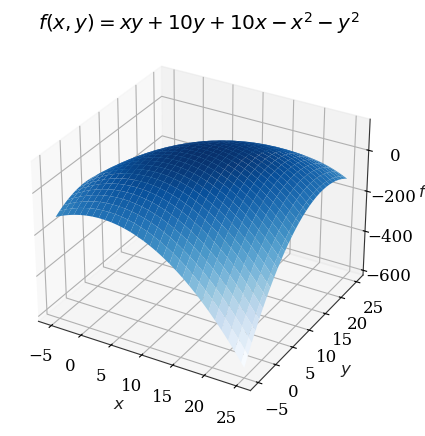

In [11]:
x = np.linspace(-5, 25, 60); y = np.linspace(-5, 25, 60)
X, Y = np.meshgrid(x, y)
Z = X*Y + 10*Y + 10*X - X**2 - Y**2

fig = plt.figure(figsize=(5, 4.9))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap="Blues", edgecolor="none")
ax.scatter([10], [10], [100], color=AMBER, s=40)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$f$")
ax.set_title(r"$f(x,y)=xy+10y+10x-x^2-y^2$")
savefig(fig, "two-unknowns-surface.png")
plt.show()

Substitution method: the deck solves the first FOC for $y(x) = 2x-10$ and
substitutes back in, giving $f(x,y(x)) = -3x^2+60x-200$, peaking at
$x=10$ (matching the surface above: $f(10,10)=100$).

saved ..\slides\02_constrained-optimization\figs\substitution-method-graph.png


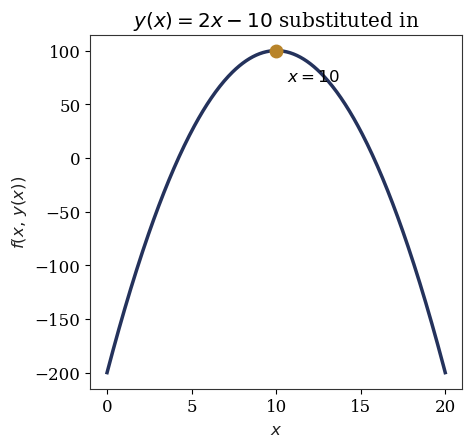

In [12]:
x = np.linspace(0, 20, 400)
g = -3*x**2 + 60*x - 200
xstar = 10

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot(x, g, color=NAVY, lw=2.5)
ax.plot(xstar, -3*xstar**2 + 60*xstar - 200, "o", color=AMBER, ms=9, zorder=5)
ax.annotate(f"$x={xstar}$", (xstar, -3*xstar**2 + 60*xstar - 200),
            textcoords="offset points", xytext=(8, -22))
ax.set_xlabel("$x$"); ax.set_ylabel(r"$f(x,\,y(x))$")
ax.set_title(r"$y(x)=2x-10$ substituted in")
savefig(fig, "substitution-method-graph.png")
plt.show()

## Utility as a Multivariable Function

saved ..\slides\02_constrained-optimization\figs\utility-surface.png


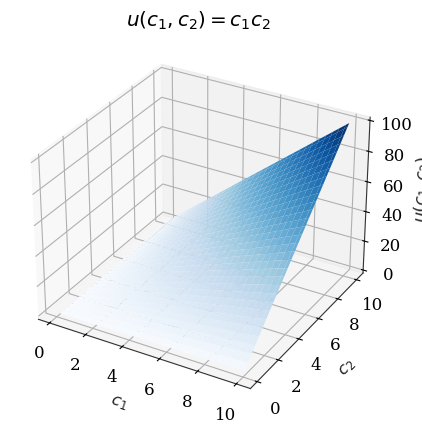

In [13]:
c1 = np.linspace(0.1, 10, 60); c2 = np.linspace(0.1, 10, 60)
C1, C2 = np.meshgrid(c1, c2)
U = C1 * C2

fig = plt.figure(figsize=(5, 4.9))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(C1, C2, U, cmap="Blues", edgecolor="none")
ax.set_xlabel("$c_1$"); ax.set_ylabel("$c_2$"); ax.set_zlabel("$u(c_1,c_2)$")
ax.set_title(r"$u(c_1,c_2)=c_1 c_2$")
savefig(fig, "utility-surface.png")
plt.show()

## Interactive Demos (for live use in class)

These aren't part of the static figure set above -- they're proof-of-concept
demos for showing live in lecture. The `ipywidgets` sliders need a running
Jupyter kernel (Jupyter Lab/Notebook, VS Code, or Colab); the `plotly`
surface renders as embedded JS, so it also survives an HTML export
(`jupyter nbconvert --to html`).

### Demo 1: Profit Maximization -- price and cost-curvature sliders

In [14]:
import ipywidgets as widgets

def plot_profit(P=10, c=1.0):
    q = np.linspace(0, 15, 400)
    pi = P*q - 10 - c*q**2
    qstar = P / (2*c)
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.plot(q, pi, color=NAVY, lw=2.5)
    ax.axvline(qstar, color=AMBER, ls="--", lw=1)
    ax.plot(qstar, P*qstar - 10 - c*qstar**2, "o", color=AMBER, ms=9)
    ax.annotate(f"$q^*={qstar:.2f}$", (qstar, P*qstar - 10 - c*qstar**2),
                textcoords="offset points", xytext=(10, -18))
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_ylim(-30, 60)
    ax.set_xlabel("$q$"); ax.set_ylabel(r"$\pi(q)$")
    ax.set_title(fr"$\pi(q) = {P}q - 10 - {c}q^2$")
    plt.show()

widgets.interact(plot_profit,
                  P=widgets.FloatSlider(value=10, min=2, max=30, step=1, description="Price P"),
                  c=widgets.FloatSlider(value=1.0, min=0.2, max=3, step=0.1, description="Cost curvature c"));

interactive(children=(FloatSlider(value=10.0, description='Price P', max=30.0, min=2.0, step=1.0), FloatSlider…

### Demo 2: Isoquant / MRTS -- output level and evaluation point sliders

In [15]:
def plot_isoquant(c=100, x0=10):
    x = np.linspace(2, 60, 400)
    y = c / x
    y0 = c / x0
    slope = -y0 / x0
    fig, ax = plt.subplots(figsize=(6, 4.4))
    ax.plot(x, y, color=NAVY, lw=2.5, label=f"$xy={c}$")
    xr = np.linspace(max(2, x0 - 5), x0 + 5, 10)
    ax.plot(xr, y0 + slope*(xr - x0), color=AMBER, ls="--", lw=1.6)
    ax.plot(x0, y0, "o", color=AMBER, ms=8)
    ax.annotate(f"MRTS = {-slope:.2f}", (x0, y0), textcoords="offset points", xytext=(8, 8))
    ax.set_xlim(0, 60); ax.set_ylim(0, 30)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
    ax.legend()
    plt.show()

widgets.interact(plot_isoquant,
                  c=widgets.IntSlider(value=100, min=20, max=300, step=10, description="Output q"),
                  x0=widgets.FloatSlider(value=10, min=3, max=40, step=1, description="Evaluate at x"));

interactive(children=(IntSlider(value=100, description='Output q', max=300, min=20, step=10), FloatSlider(valu…

### Demo 3: Rotatable 3-D Surface (Plotly)

In [16]:
import plotly.graph_objects as go

x = np.linspace(-5, 15, 60); y = np.linspace(0, 20, 60)
X, Y = np.meshgrid(x, y)
Z = 100 - (X - 5)**2 - (Y - 10)**2

fig = go.Figure(data=[go.Surface(x=x, y=y, z=Z, colorscale="Blues")])
fig.update_layout(
    title="f(x,y) = 100 - (x-5)^2 - (y-10)^2 -- drag to rotate",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="f(x,y)"),
    width=650, height=550, margin=dict(l=0, r=0, t=40, b=0),
)
fig.show()

## Next Steps

- Review these against the current `media/` PNGs in
  `slides/02_constrained-optimization/`. If they look good, swap them in
  (they're saved to `../slides/02_constrained-optimization/figs/` here, not written directly into the
  deck's `media/` folder, so nothing changes there until you decide to).
- If this proves out, the same approach extends naturally to the rest of
  Topic 2's remaining sub-chunks (Lagrange method, corner solutions) and to
  later topics as they're converted.
- The `ipywidgets`/`plotly` demos above are candidates for live in-class use
  -- e.g., varying the price in the profit-maximization demo, or the output
  level in the isoquant demo, to make comparative statics tangible.

## The hill along the fence

The consumer problem as a walk along the budget line ($u = c_1 c_2$, $p_1 = 2$, $p_2 = 3$, $I = 120$). Left: from bundle A the better bundles lie further along the line; right: utility measured along the line is a one-dimensional hill whose slope is $p_1(MU_1/p_1 - MU_2/p_2)$.

saved ..\slides\02_constrained-optimization\figs\hill-along-the-fence.png


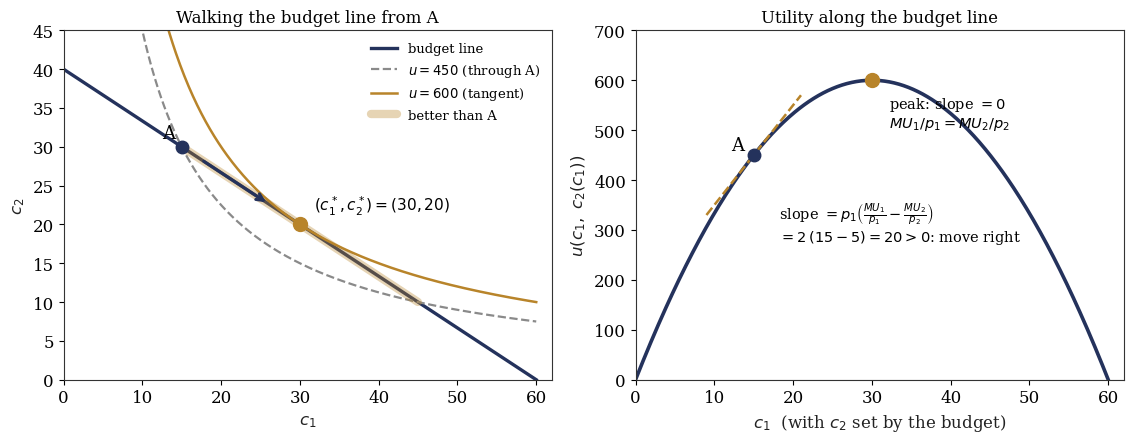

In [17]:
# "The hill along the fence": the consumer problem viewed as a walk along the
# budget line. Left: budget line on the indifference map, starting bundle A,
# the stretch of budget line better than A, and the optimum. Right: utility
# measured along the budget line -- a one-dimensional hill.
GREY = "#8a8a8a"
p1, p2, I = 2.0, 3.0, 120.0
A = (15.0, 30.0)                       # on the budget line: 2(15) + 3(30) = 120
opt = (I / (2 * p1), I / (2 * p2))     # (30, 20)
uA, uopt = A[0] * A[1], opt[0] * opt[1]

c1 = np.linspace(0.01, I / p1, 500)
c2_budget = (I - p1 * c1) / p2
u_along = c1 * c2_budget

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

# ---- left: the walk on the indifference map
ax = axes[0]
ax.plot(c1, c2_budget, color=NAVY, lw=2.4, label="budget line")
cc = np.linspace(6, 60, 400)
ax.plot(cc, uA / cc, color=GREY, lw=1.6, ls="--", label=f"$u = {uA:.0f}$ (through A)")
ax.plot(cc, uopt / cc, color=AMBER, lw=1.8, label=f"$u = {uopt:.0f}$ (tangent)")
better = (c1 >= 15) & (c1 <= 45)
ax.plot(c1[better], c2_budget[better], color=AMBER, lw=6, alpha=0.35,
        solid_capstyle="round", label="better than A")
ax.plot(*A, "o", color=NAVY, ms=9, zorder=6)
ax.annotate("A", A, textcoords="offset points", xytext=(-14, 6), fontsize=13)
ax.plot(*opt, "o", color=AMBER, ms=10, zorder=6)
ax.annotate(r"$(c_1^*, c_2^*) = (30, 20)$", opt, textcoords="offset points",
            xytext=(10, 10), fontsize=11)
ax.annotate("", xy=(26, (I - p1 * 26) / p2), xytext=(17.5, (I - p1 * 17.5) / p2),
            arrowprops=dict(arrowstyle="->", color=NAVY, lw=2.2))
ax.set_xlim(0, 62); ax.set_ylim(0, 45)
ax.set_xlabel("$c_1$"); ax.set_ylabel("$c_2$")
ax.set_title("Walking the budget line from A", fontsize=12)
ax.legend(frameon=False, fontsize=9.5, loc="upper right")

# ---- right: utility along the budget line
ax = axes[1]
ax.plot(c1, u_along, color=NAVY, lw=2.6)
ax.plot(A[0], uA, "o", color=NAVY, ms=9, zorder=6)
ax.annotate("A", (A[0], uA), textcoords="offset points", xytext=(-16, 4), fontsize=13)
slopeA = p1 * (A[1] / p1 - A[0] / p2)  # = p1 (MU1/p1 - MU2/p2) = 20
seg = np.linspace(A[0] - 6, A[0] + 6, 2)
ax.plot(seg, uA + slopeA * (seg - A[0]), color=AMBER, lw=1.8, ls="--")
ax.annotate("slope $= p_1\\left(\\frac{MU_1}{p_1} - \\frac{MU_2}{p_2}\\right)$\n"
            "$= 2\\,(15 - 5) = 20 > 0$: move right",
            (A[0], uA), textcoords="offset points", xytext=(18, -62), fontsize=10.5)
ax.plot(opt[0], uopt, "o", color=AMBER, ms=10, zorder=6)
ax.annotate("peak: slope $= 0$\n$MU_1/p_1 = MU_2/p_2$", (opt[0], uopt),
            textcoords="offset points", xytext=(12, -34), fontsize=10.5)
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlim(0, 62); ax.set_ylim(0, 700)
ax.set_xlabel("$c_1$  (with $c_2$ set by the budget)")
ax.set_ylabel(r"$u(c_1,\ c_2(c_1))$")
ax.set_title("Utility along the budget line", fontsize=12)

fig.tight_layout()
savefig(fig, "hill-along-the-fence.png")
plt.show()
